EDA 1 — Overall demand over time
How has overall sales demand changed over time? Are there visible trends, structural changes, seasonality, or unusual periods?

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [6]:
DATA_DIR = Path("../data/raw")
train_df = pd.read_csv(DATA_DIR / "train.csv")

/var/folders/v7/4qxnxc414ll92wrtcvlncx980000gp/T/ipykernel_40579/2939570863.py:2: DtypeWarning: Columns (5: onpromotion) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv(DATA_DIR / "train.csv")


In [7]:
train_df.head(10)

,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,0,2013-01-01,25,103665,7.0,NaN
1,1,2013-01-01,25,105574,1.0,NaN
2,2,2013-01-01,25,105575,2.0,NaN
3,3,2013-01-01,25,108079,1.0,NaN
4,4,2013-01-01,25,108701,1.0,NaN
5,5,2013-01-01,25,108786,3.0,NaN
6,6,2013-01-01,25,108797,1.0,NaN
7,7,2013-01-01,25,108952,1.0,NaN
8,8,2013-01-01,25,111397,13.0,NaN
9,9,2013-01-01,25,114790,3.0,NaN


In [8]:
daily_sales_df = train_df.groupby("date")["unit_sales"].sum().reset_index()
daily_sales_df.head(50)

,date,unit_sales
0,2013-01-01,2511.619
1,2013-01-02,496092.418
2,2013-01-03,361429.231
3,2013-01-04,354459.677
4,2013-01-05,477350.121
5,2013-01-06,519695.401
6,2013-01-07,336122.801
7,2013-01-08,318347.778
8,2013-01-09,302530.809
9,2013-01-10,258982.003


In [10]:
print(f"Shape of daily_sales_df: {daily_sales_df.shape}")
print(f"Minimum date in daily_sales_df: {daily_sales_df['date'].min()}")
print(f"Maximum date in daily_sales_df: {daily_sales_df['date'].max()}")

Shape of daily_sales_df: (1684, 2)
Minimum date in daily_sales_df: 2013-01-01
Maximum date in daily_sales_df: 2017-08-15


In [11]:
daily_sales_df["unit_sales"].describe()

count    1.684000e+03
mean     6.375358e+05
std      2.343921e+05
min      2.511619e+03
25%      4.425738e+05
50%      6.321889e+05
75%      7.859455e+05
max      1.463084e+06
Name: unit_sales, dtype: float64

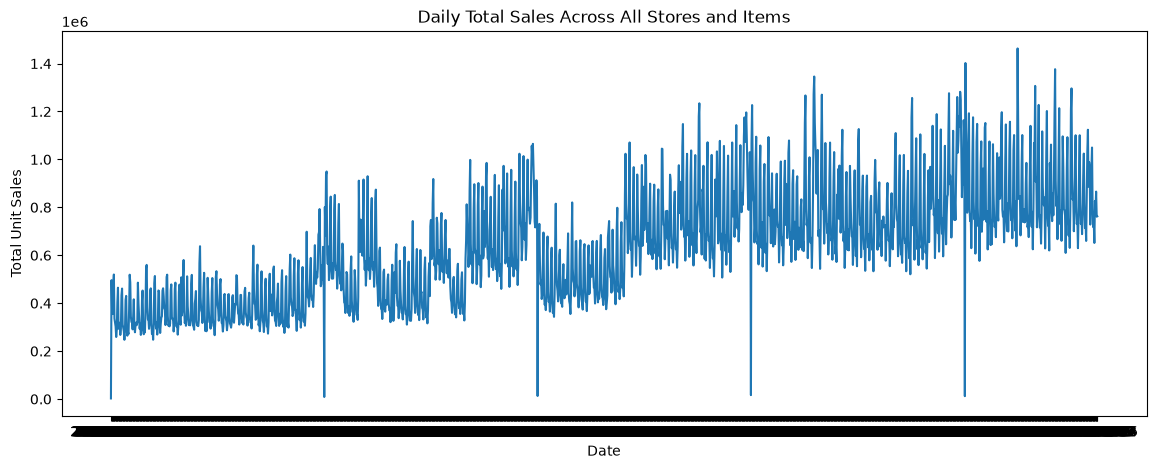

In [12]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales_df["date"],
    daily_sales_df["unit_sales"]
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")
plt.title("Daily Total Sales Across All Stores and Items")

plt.show()

In [16]:
daily_sales_df["date"] = pd.to_datetime(daily_sales_df["date"])

In [17]:
monthly_sales_df = (
    daily_sales_df
    .set_index("date")
    .resample("ME")["unit_sales"]
    .sum()
    .reset_index()
)

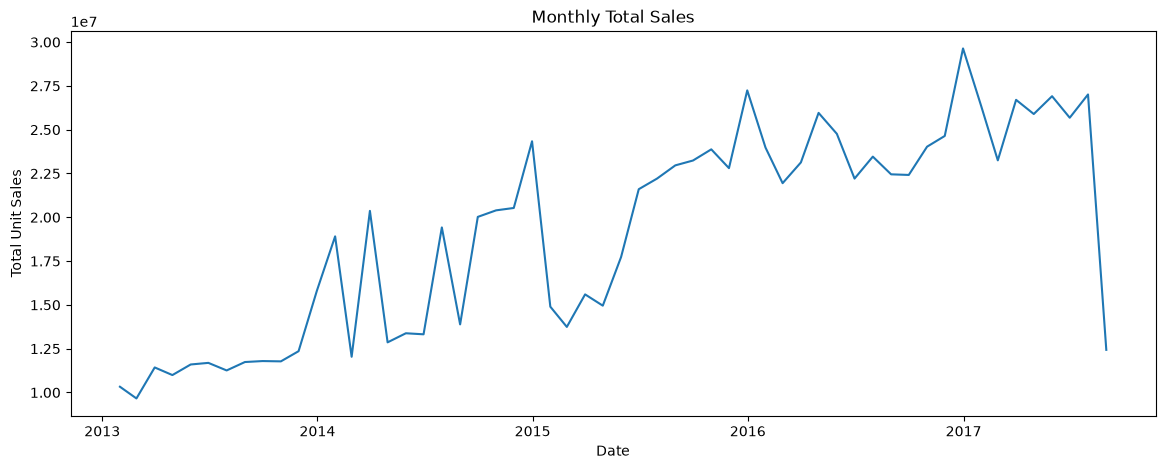

In [18]:
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales_df["date"], monthly_sales_df["unit_sales"])
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")
plt.title("Monthly Total Sales")
plt.show()

In [33]:
sample_period_df = daily_sales_df[(daily_sales_df["date"] >= "2014-07-01") & (daily_sales_df["date"] <= "2014-08-15")]

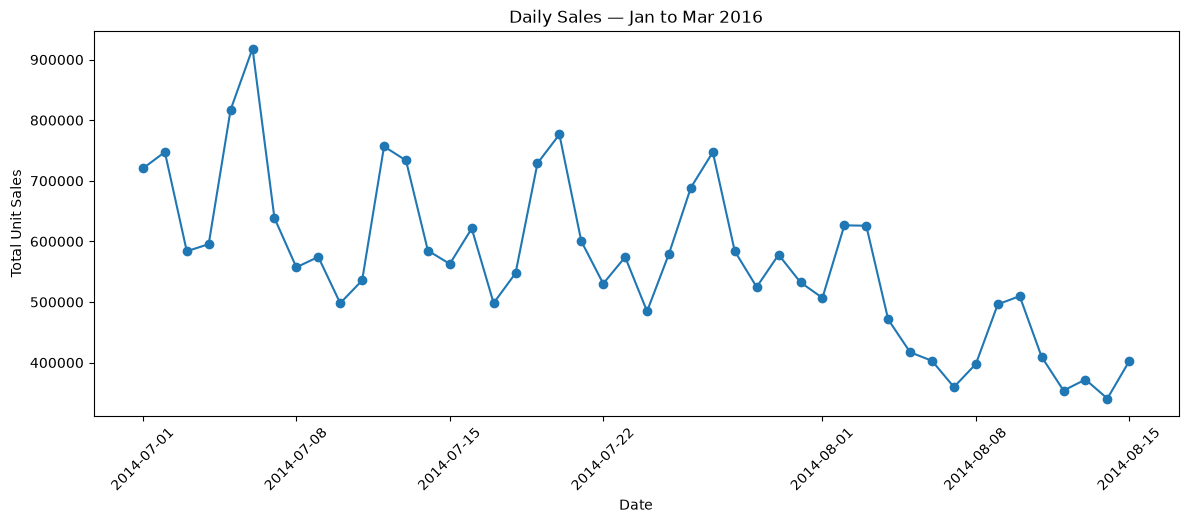

In [34]:
plt.figure(figsize=(14, 5))
plt.plot(
    sample_period_df["date"],
    sample_period_df["unit_sales"],
    marker="o"
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")
plt.title("Daily Sales — Jan to Mar 2016")
plt.xticks(rotation=45)
plt.show()

In [35]:
daily_sales_df["day_of_week"] = daily_sales_df["date"].dt.day_name()

In [42]:
expected_days = pd.date_range(
    daily_sales_df["date"].min(),
    daily_sales_df["date"].max(),
    freq="D"
)

len(expected_days.unique())

1688

In [44]:
observed_days = pd.DatetimeIndex(daily_sales_df["date"])

missing_days = expected_days.difference(observed_days)

missing_days

DatetimeIndex(['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25'], dtype='datetime64[us]', freq=None)

### Calendar coverage

The training data spans 1,688 calendar days, of which 1,684 are
observed. The four missing dates are:

- 2013-12-25
- 2014-12-25
- 2015-12-25
- 2016-12-25

All missing dates correspond to Christmas Day, suggesting that these
calendar gaps are systematic rather than random missing observations.
They are retained as missing dates at this stage rather than being
automatically interpreted as zero sales.

In [47]:
daily_sales_df.groupby("day_of_week")["unit_sales"].mean().reindex([
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
]).reset_index().rename(columns={"unit_sales": "average_unit_sales"})

,day_of_week,average_unit_sales
0,Monday,617479.929934
1,Tuesday,569916.489993
2,Wednesday,593244.190965
3,Thursday,505256.688612
4,Friday,579573.986125
5,Saturday,772147.340838
6,Sunday,825218.075771


In [48]:
daily_sales_df["year"] = daily_sales_df["date"].dt.year

In [54]:
daily_sales_by_year = daily_sales_df.pivot_table(
    index="year",
    columns="day_of_week",
    values="unit_sales",
    aggfunc="mean"
)


day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

daily_sales_by_year = daily_sales_by_year[day_order]

daily_sales_by_year

day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
year,,,,,,,
2013,376418.423115,331870.664170,342623.420098,309326.613538,347734.079788,4.837995e+05,5.087803e+05
2014,561422.938558,518633.832777,529628.056202,456010.257565,507978.425690,7.000115e+05,7.532478e+05
2015,633742.627942,594721.348385,620535.306904,525293.515698,597275.065098,7.977497e+05,8.641403e+05
2016,764039.954115,711296.754308,742916.980192,626329.037288,725051.017057,9.406469e+05,1.028100e+06
2017,829097.516364,771174.082818,810468.921844,672200.998625,803499.192531,1.037252e+06,1.062379e+06


A strong and persistent weekly sales pattern is observed across all years, with demand consistently increasing on weekends and typically peaking on Sundays.

## EDA 2 — Long-term Trend & Annual Seasonality

In [55]:
daily_sales_df["month"] = daily_sales_df["date"].dt.month

In [56]:
monthly_sales_df = daily_sales_df.groupby(["year", "month"])["unit_sales"].mean().reset_index()
monthly_sales_df

,year,month,unit_sales
0,2013,1,333142.314065
1,2013,2,344962.849179
2,2013,3,368661.194742
3,2013,4,366448.757967
4,2013,5,374119.419581
5,2013,6,389644.535400
6,2013,7,363141.890548
7,2013,8,378638.320000
8,2013,9,393097.741100
9,2013,10,379858.689032


In [65]:
yearly_monthly_mean_sales = monthly_sales_df.pivot_table(
    index="year",
    columns="month",
    values="unit_sales",
    aggfunc="mean"
)

yearly_monthly_mean_sales = yearly_monthly_mean_sales.rename(columns={
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
})

yearly_monthly_mean_sales

month,January,February,March,April,May,June,July,August,September,October,November,December
year,,,,,,,,,,,,
2013,333142.314065,344962.849179,368661.194742,366448.757967,374119.419581,389644.535400,363141.890548,378638.320000,393097.741100,379858.689032,411884.343400,526745.404967
2014,610052.861326,429940.736968,656954.290961,428708.335220,431605.911668,443998.405743,626512.582068,447908.045755,667413.803810,657936.696358,684387.806853,811348.278857
2015,480545.840548,490799.816036,503180.887677,498502.005700,571947.233677,720103.944967,716439.291516,740763.685194,774696.082567,770266.505290,760165.078900,908132.522533
2016,773476.963968,756807.165586,746186.383355,865335.936867,798819.524452,740307.286000,756860.368645,724271.429613,747248.236567,775173.800581,821419.239867,987940.129400
2017,849294.159226,830361.120571,861419.377129,863176.849700,868123.846774,856092.270867,871337.889226,828888.195933,NaN,NaN,NaN,NaN


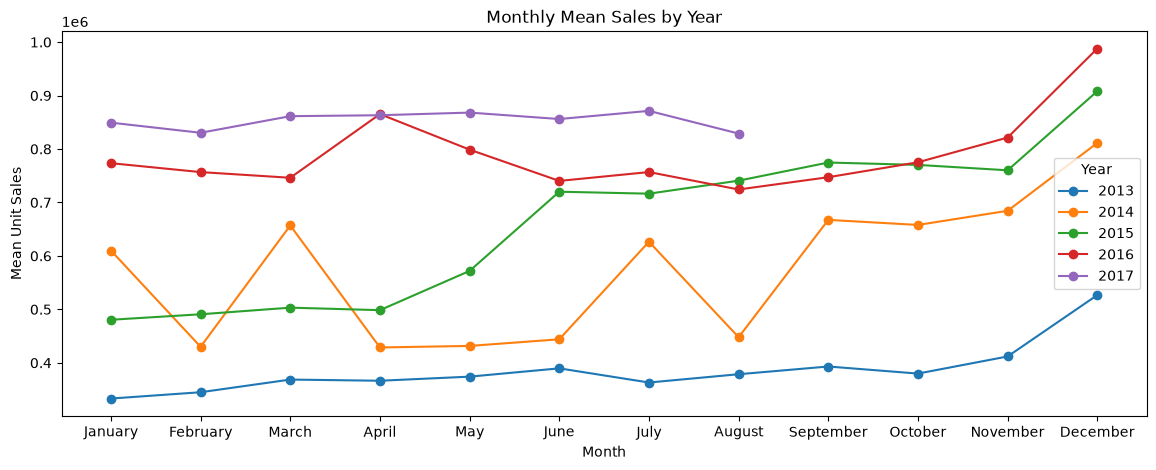

In [70]:
plt.figure(figsize=(14, 5))
for year, monthly_sales in yearly_monthly_mean_sales.iterrows():
    plt.plot(
        yearly_monthly_mean_sales.columns,
        monthly_sales,
        marker="o",
        label=year
    )

plt.xlabel("Month")
plt.ylabel("Mean Unit Sales")
plt.title("Monthly Mean Sales by Year")
plt.legend(title="Year")
plt.show()

In [73]:
yearly_monthly_mean_sales_trend = yearly_monthly_mean_sales.div(yearly_monthly_mean_sales.mean(axis=1), axis=0)
yearly_monthly_mean_sales_trend

month,January,February,March,April,May,June,July,August,September,October,November,December
year,,,,,,,,,,,,
2013,0.863371,0.894005,0.955422,0.949688,0.969568,1.009803,0.941118,0.981279,1.018752,0.984442,1.067439,1.365113
2014,1.061459,0.748073,1.143065,0.745929,0.750971,0.772533,1.090098,0.779336,1.161264,1.144774,1.190797,1.411702
2015,0.726674,0.742180,0.760902,0.753827,0.864889,1.088930,1.083388,1.120171,1.171483,1.164785,1.149509,1.373263
2016,0.977657,0.956587,0.943162,1.093764,1.009689,0.935731,0.956654,0.915462,0.944504,0.979802,1.038255,1.248733
2017,0.994971,0.972791,1.009176,1.011235,1.017031,1.002935,1.020796,0.971065,NaN,NaN,NaN,NaN


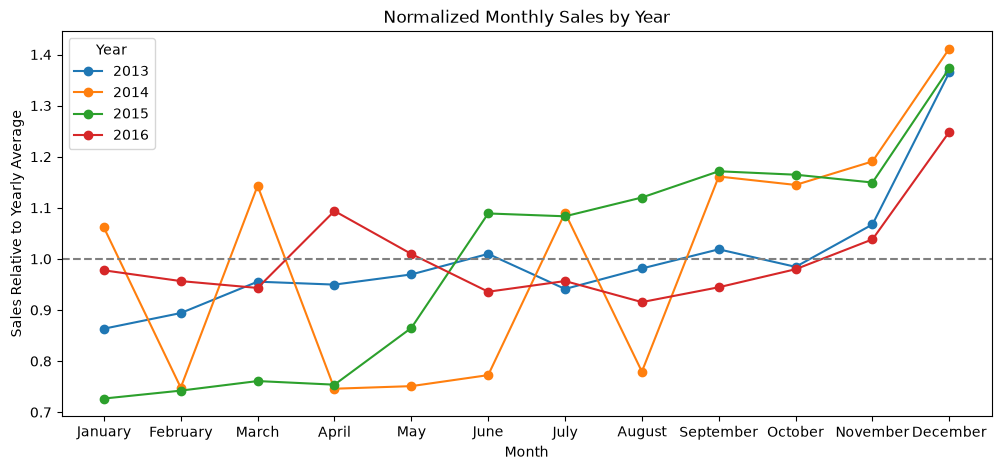

In [74]:
plt.figure(figsize=(12, 5))

for year, monthly_sales in yearly_monthly_mean_sales_trend.loc[2013:2016].iterrows():
    plt.plot(
        monthly_sales.index,
        monthly_sales.values,
        marker="o",
        label=year
    )

plt.axhline(y=1, color="gray", linestyle="--")

plt.xlabel("Month")
plt.ylabel("Sales Relative to Yearly Average")
plt.title("Normalized Monthly Sales by Year")
plt.legend(title="Year")
plt.show()

Monthly sales exhibit a recurring December peak across 2013–2016. However, other monthly patterns are less consistent, and further analysis is needed to distinguish annual seasonality from underlying sales growth.

## EDA 3 — What is driving overall sales growth?


In [83]:
train_df["date"] = pd.to_datetime(train_df["date"])
monthly_active_stores = train_df.groupby([pd.Grouper(key="date", freq="MS")])["store_nbr"].nunique().reset_index(name="active_stores")
monthly_active_stores.head()

,date,active_stores
0,2013-01-01,46
1,2013-02-01,46
2,2013-03-01,46
3,2013-04-01,46
4,2013-05-01,47


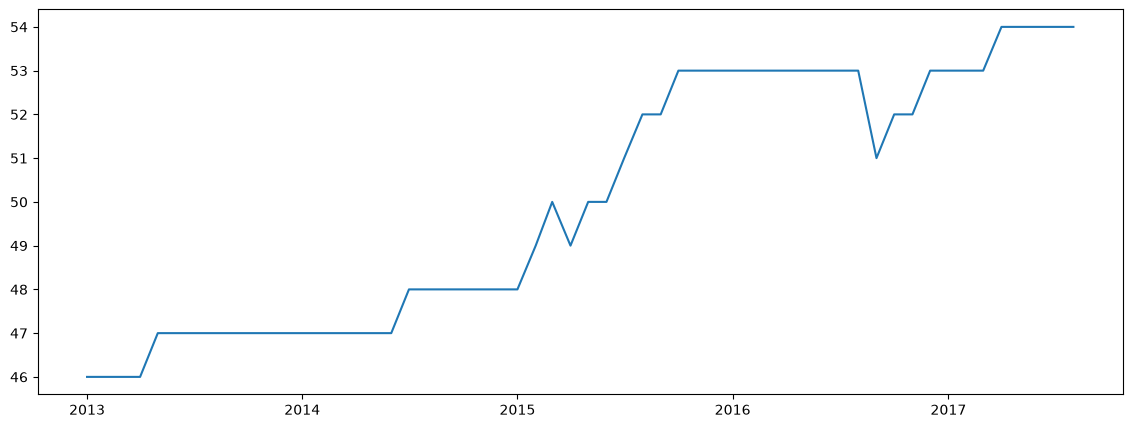

In [85]:
plt.figure(figsize=(14, 5))
plt.plot(monthly_active_stores["date"], monthly_active_stores["active_stores"]) 


In [111]:
train_df.columns

Index(['id', 'date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion'], dtype='str')

In [112]:
daily_active_stores = train_df.groupby("date")["store_nbr"].nunique().reset_index(name="active_stores")
daily_active_stores.head()

,date,active_stores
0,2013-01-01,1
1,2013-01-02,46
2,2013-01-03,46
3,2013-01-04,46
4,2013-01-05,46


In [117]:
daily_sales_df.drop(columns=["active_stores_x", "active_stores_y"], inplace=True)

In [ ]:
daily_sales_df = daily_sales_df.merge(
    daily_active_stores,
    on="date",
    how="left",
    validate="one_to_one"
)

MergeError: Passing 'suffixes' which cause duplicate columns {'active_stores_x', 'active_stores_y'} is not allowed.

In [119]:
daily_sales_df.columns

Index(['date', 'unit_sales', 'day_of_week', 'year', 'month', 'active_stores'], dtype='str')

In [120]:
daily_sales_df["sales_per_store"] = daily_sales_df["unit_sales"] / daily_sales_df["active_stores"]
daily_sales_df

,date,unit_sales,day_of_week,year,month,active_stores,sales_per_store
0,2013-01-01,2511.619,Tuesday,2013,1,1,2511.619000
1,2013-01-02,496092.418,Wednesday,2013,1,46,10784.617783
2,2013-01-03,361429.231,Thursday,2013,1,46,7857.157196
3,2013-01-04,354459.677,Friday,2013,1,46,7705.645152
4,2013-01-05,477350.121,Saturday,2013,1,46,10377.176543
...,...,...,...,...,...,...,...
1679,2017-08-11,826373.722,Friday,2017,8,54,15303.217074
1680,2017-08-12,792630.535,Saturday,2017,8,54,14678.343241
1681,2017-08-13,865639.677,Sunday,2017,8,54,16030.364389
1682,2017-08-14,760922.406,Monday,2017,8,54,14091.155667
